In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Context effect — additive or multiplicative?

Nir's list (2026-10-11), item 8. No new runs. The default (`shopping`, no contract) is the reference.
A context (a frame / persona, or a contract for comparison) changes the 11 feature weights
`w0 → w1` (FeatureBT, centred within each feature). Two ways to read the change:

- **default = 0, additive:** `Δ = w1 − w0`, per level.
- **default = 1, multiplicative:** `w1 ≈ λ · w0`. One λ for all features (global), or one per
  feature (`λ_f`, least squares through the origin inside that feature). λ = 1 unchanged, 0 erased,
  > 1 louder, < 0 reversed.

**Rescaling share** = cos²(Δ, w0): the part of the change that lies along the default weights,
i.e. what one global λ explains. Near 100% → the context only turns the volume up or down;
near 0 → it adds something the default did not have (a targeted, additive change).

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/context"
os.makedirs(FIGDIR, exist_ok=True)
LEVELS = {"brand": ["ASUS", "Apple", "Dell", "HP", "Lenovo"], "screen": ["13-inch", "14-inch", "16-inch"],
          "ram": ["4GB", "8GB", "16GB"]}
LV = [(f, l) for f in LEVELS for l in LEVELS[f]]
FOLDERS = ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_persona"]
FRAMES = ["bare", "student_only", "no_money", "student", "role_none", "role_student", "windows", "designer", "editor"]
CONTRACTS = ["screen=13-inch", "screen=14-inch", "screen=16-inch", "ram=4GB", "ram=8GB", "ram=16GB"]
MODEL_ORDER = [("qwen", s) for s in ("0.5", "7", "32", "72")] + [("gemma", s) for s in ("1", "4", "12", "27")]


def load():
    """{(family, size, context): w vector (11)}. context = frame name (no contract) or constraints_id
    (shopping frame); 'default' = shopping, no contract."""
    W = {}
    for base in FOLDERS:
        for r in sorted(os.listdir(base)):
            cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
            if not (os.path.isfile(cf) and os.path.isfile(sc)):
                continue
            c = json.load(open(cf))
            m = (c["model_family"], str(c["model_size"]))
            if m not in MODEL_ORDER:
                continue
            fr, cid = c["frame"]["name"], c["constraints_id"]
            if fr == "shopping":
                ctx = "default" if cid == "none" else cid if cid in CONTRACTS else None
            else:
                ctx = fr if (cid == "none" and fr in FRAMES) else None
            if ctx is None:
                continue
            d = pd.read_csv(sc)
            if len(d) != 9900:
                continue
            assert (m + (ctx,)) not in W, f"two complete runs for {m} {ctx}"
            f = FeatureBT(r2_warn=None).fit(d)
            W[m + (ctx,)] = np.array([f.weights_[ft][l] for ft, l in LV])
    return W


W = load()
print(len(W), "runs")

80 runs


## The decomposition, every (model, context)

In [3]:
def feat_slice(f):
    i = [k for k, (ft, _) in enumerate(LV) if ft == f]
    return slice(i[0], i[-1] + 1)


def decompose(w0, w1):
    d = w1 - w0
    lam = w1 @ w0 / (w0 @ w0)
    out = {"lambda": lam, "|change| / |default|": np.linalg.norm(d) / np.linalg.norm(w0),
           "rescaling share %": 100 * (d @ w0) ** 2 / ((d @ d) * (w0 @ w0)) if d @ d > 0 else np.nan}
    for f in LEVELS:
        s = feat_slice(f)
        out[f"lambda {f}"] = w1[s] @ w0[s] / (w0[s] @ w0[s])
    # how much of w1 the per-feature multiplicative model explains
    fit = np.concatenate([w0[feat_slice(f)] * out[f"lambda {f}"] for f in LEVELS])
    out["R2 per-feature lambda"] = 1 - ((w1 - fit) ** 2).sum() / (w1 ** 2).sum()
    out["R2 global lambda"] = 1 - ((w1 - lam * w0) ** 2).sum() / (w1 ** 2).sum()
    return out


rows = []
for (fam, size, ctx), w1 in W.items():
    if ctx == "default" or (fam, size, "default") not in W:
        continue
    rows.append({"model": f"{fam}-{size}B", "_m": MODEL_ORDER.index((fam, size)),
                 "kind": "contract" if ctx in CONTRACTS else "frame", "context": ctx,
                 "_c": (FRAMES + CONTRACTS).index(ctx), **decompose(W[(fam, size, "default")], w1)})
T = pd.DataFrame(rows).sort_values(["_m", "_c"]).drop(columns=["_m", "_c"]).reset_index(drop=True)
T.to_csv(os.path.join(FIGDIR, "context_decomposition.csv"), index=False)
pd.set_option("display.width", 250)
print(T.round(2).to_string(index=False))

    model     kind        context  lambda  |change| / |default|  rescaling share %  lambda brand  lambda screen  lambda ram  R2 per-feature lambda  R2 global lambda
qwen-0.5B    frame           bare    0.92                  0.63               1.56          0.49           1.18        1.17                   0.77              0.68
qwen-0.5B contract screen=13-inch    0.15                  2.21              14.73          0.53          -7.62        0.68                   0.87              0.01
qwen-0.5B contract screen=14-inch    0.95                  2.07               0.06          0.53           5.80        0.74                   0.45              0.17
qwen-0.5B contract screen=16-inch    1.46                  2.16               4.58          0.60           3.65        1.81                   0.42              0.32
qwen-0.5B contract        ram=4GB   -0.98                  2.87              47.29          1.45           0.89       -2.73                   0.96              0.18
qwen-0.5B 

## F1 — qwen-32B and qwen-72B, every context: additive view (left) and multiplicative view (right)

Left: Δ per level (default = 0). Right: λ per feature and globally (default = 1), and the rescaling
share. Rows: the frames (personas, bare), then the six single contracts for comparison.

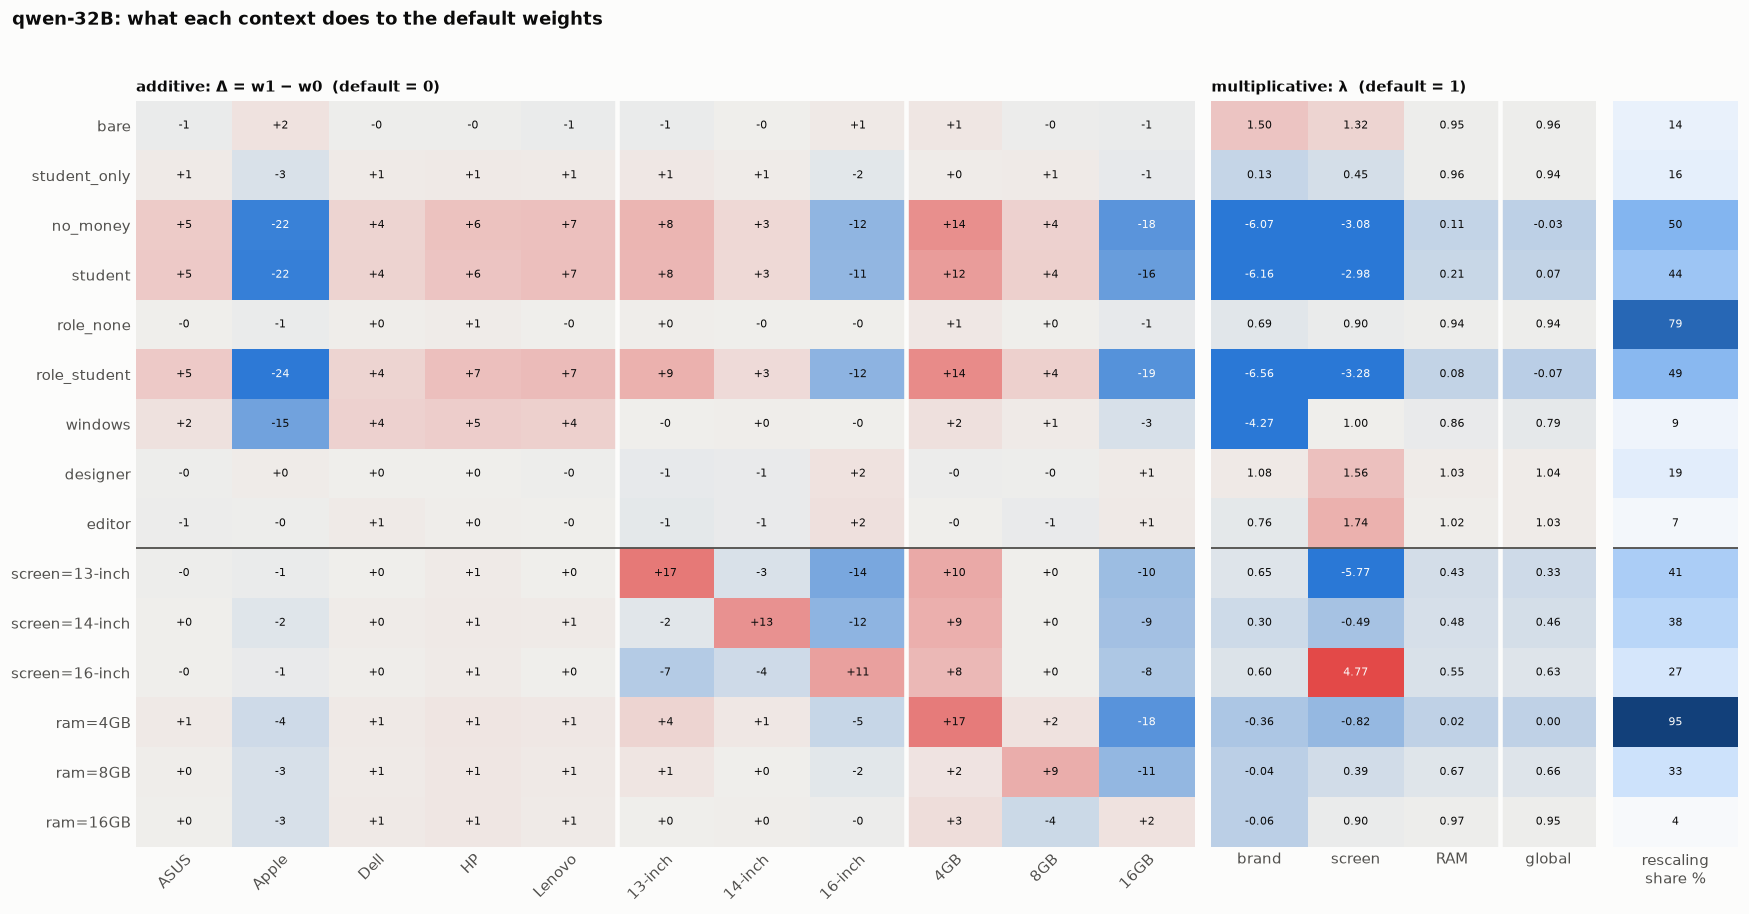

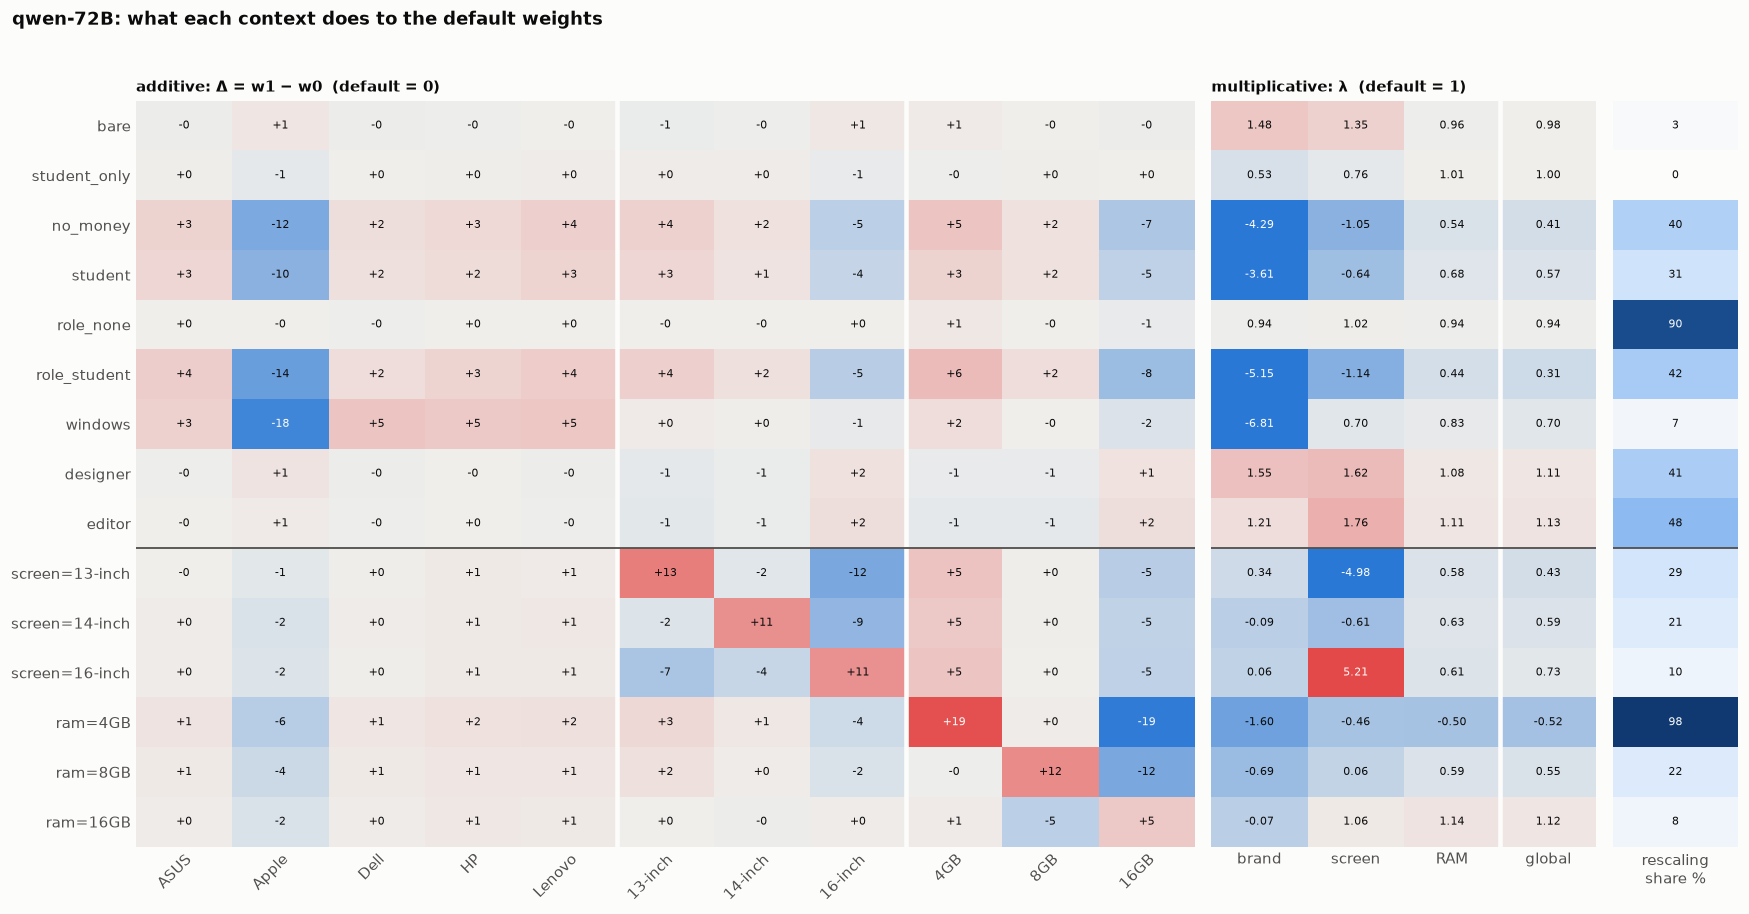

In [4]:
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])


def cell_text(ax, M, fmt, cmap, norm):
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if np.isnan(v):
                continue
            r, g, b, _ = cmap(norm(v))
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=7.5,
                    color=SURFACE if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else INK)


def clean(ax):
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)


for fam, size in [("qwen", "32"), ("qwen", "72")]:
    ctxs = [c for c in FRAMES + CONTRACTS if (fam, size, c) in W]
    w0 = W[(fam, size, "default")]
    A = np.array([W[(fam, size, c)] - w0 for c in ctxs])
    sub = T[(T.model == f"{fam}-{size}B")].set_index("context").loc[ctxs]
    Lcols = ["lambda brand", "lambda screen", "lambda ram", "lambda"]
    L = sub[Lcols].values.astype(float)
    S = sub[["rescaling share %"]].values.astype(float)

    fig, axes = plt.subplots(1, 3, figsize=(16, 0.42 * len(ctxs) + 1.8), gridspec_kw={"width_ratios": [11, 4, 1.3]})
    va = np.ceil(np.abs(A).max())
    na = TwoSlopeNorm(vmin=-va, vcenter=0, vmax=va)
    axes[0].imshow(A, cmap=DIV, norm=na, aspect="auto")
    cell_text(axes[0], A, lambda v: f"{v:+.0f}", DIV, na)
    axes[0].set_xticks(range(len(LV)), [l for _, l in LV], rotation=45, ha="right", rotation_mode="anchor")
    axes[0].set_yticks(range(len(ctxs)), ctxs)
    axes[0].set_title("additive: Δ = w1 − w0  (default = 0)", loc="left", fontweight="bold", fontsize=10)
    for k in (5, 8):
        axes[0].axvline(k - 0.5, color=SURFACE, lw=3)

    nl = TwoSlopeNorm(vmin=-3, vcenter=1, vmax=3)                    # 1 = unchanged; clipped at +-3
    axes[1].imshow(np.clip(L, -3, 3), cmap=DIV, norm=nl, aspect="auto")
    cell_text(axes[1], L, lambda v: f"{v:.2f}", DIV, lambda v: nl(np.clip(v, -3, 3)))
    axes[1].set_xticks(range(4), ["brand", "screen", "RAM", "global"])
    axes[1].set_yticks([])
    axes[1].set_title("multiplicative: λ  (default = 1)", loc="left", fontweight="bold", fontsize=10)
    axes[1].axvline(2.5, color=SURFACE, lw=3)

    seq = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#3987e5", "#0d366b"])
    n01 = plt.Normalize(0, 100)
    axes[2].imshow(S, cmap=seq, norm=n01, aspect="auto")
    cell_text(axes[2], S, lambda v: f"{v:.0f}", seq, n01)
    axes[2].set_xticks([0], ["rescaling\nshare %"])
    axes[2].set_yticks([])
    for ax in axes:
        clean(ax)
        nf = sum(c in FRAMES for c in ctxs)
        ax.axhline(nf - 0.5, color=INK_MUTED, lw=1.2)
    fig.suptitle(f"{fam}-{size}B: what each context does to the default weights", x=0.01, y=1.02, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"C1_additive_vs_multiplicative_{fam}-{size}B.png"), facecolor=SURFACE)
    plt.show()

## F2 — every model: how big is the change, and how much of it is just volume?

One point per (model, context). x = rescaling share (100 = pure volume change), y = size of the
change relative to the default weights. Frames are filled, contracts hollow.

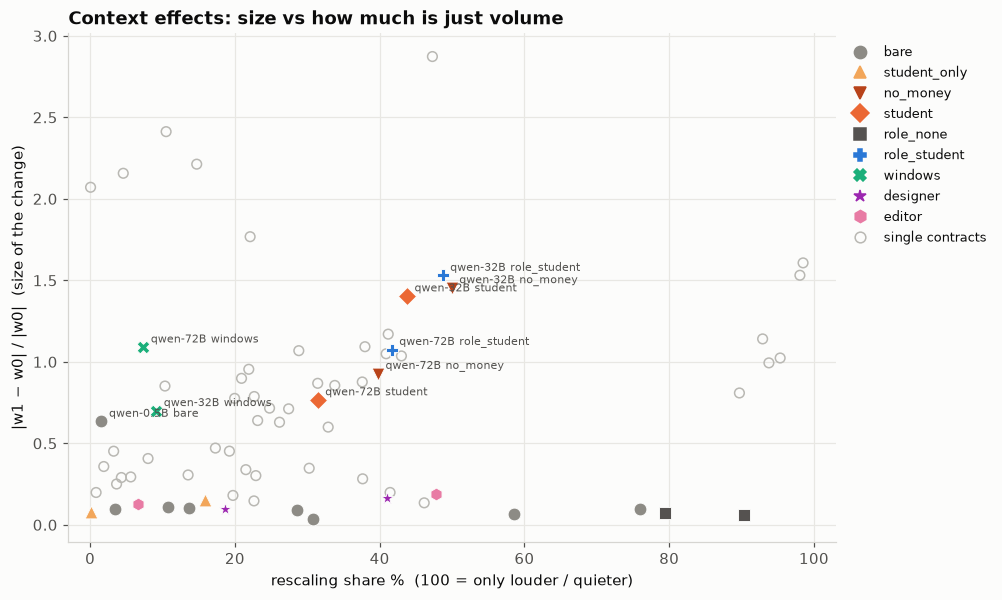

mean per context (all models that have it):
                |change| / |default|  rescaling share %  lambda  R2 global lambda  R2 per-feature lambda
context                                                                                                 
bare                            0.16              27.89    0.95              0.95                   0.97
screen=13-inch                  0.97              30.79    0.50              0.37                   0.97
screen=14-inch                  0.84              27.33    0.70              0.50                   0.61
screen=16-inch                  0.79              20.65    0.86              0.61                   0.89
ram=4GB                         1.28              81.65   -0.14              0.43                   0.69
ram=8GB                         0.84              19.03    0.86              0.59                   0.61
ram=16GB                        0.48               9.59    1.12              0.88                   0.89
student_onl

In [5]:
MARK = {"bare": "o", "student_only": "^", "no_money": "v", "student": "D", "role_none": "s", "role_student": "P",
        "windows": "X", "designer": "*", "editor": "h"}
FCOL = {"bare": "#8d8b85", "student_only": "#f2a65a", "no_money": "#b8431a", "student": "#eb6834",
        "role_none": "#555250", "role_student": "#2a78d6", "windows": "#1baf7a", "designer": "#9c27b0",
        "editor": "#e87ba4"}
fig, ax = plt.subplots(figsize=(9, 6))
ax.grid(True, color="#e8e7e3")
for _, r in T.iterrows():
    if r.kind == "frame":
        ax.scatter(r["rescaling share %"], r["|change| / |default|"], marker=MARK[r.context], s=70,
                   color=FCOL[r.context], edgecolor=SURFACE, lw=0.6, zorder=3)
    else:
        ax.scatter(r["rescaling share %"], r["|change| / |default|"], marker="o", s=40, facecolor="none",
                   edgecolor="#b9b8b3", lw=1, zorder=2)
for _, r in T[(T.kind == "frame") & (T["|change| / |default|"] > 0.5)].iterrows():
    ax.annotate(f"{r.model} {r.context}", (r["rescaling share %"], r["|change| / |default|"]), xytext=(5, 3),
                textcoords="offset points", fontsize=7.5, color=INK_MUTED)
hs = [plt.Line2D([], [], marker=MARK[c], ls="", color=FCOL[c], ms=8, label=c) for c in FRAMES]
hs.append(plt.Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="#b9b8b3", ms=7,
                     label="single contracts"))
ax.legend(handles=hs, frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_xlabel("rescaling share %  (100 = only louder / quieter)")
ax.set_ylabel("|w1 − w0| / |w0|  (size of the change)")
ax.set_xlim(-3, 103)
ax.set_title("Context effects: size vs how much is just volume", loc="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "C2_size_vs_rescaling.png"), facecolor=SURFACE)
plt.show()

print("mean per context (all models that have it):")
print(T.groupby("context", sort=False)[["|change| / |default|", "rescaling share %", "lambda", "R2 global lambda",
                                        "R2 per-feature lambda"]].mean().round(2).to_string())

---
# Per laptop: is the context an additive or a multiplicative change to the default?

Same question, one level down: not the 11 feature weights but the **45 laptops**. Each laptop's
utility is its **position-corrected Borda score** `u` = mean D against the 44 others (model-free;
on this design it is the per-laptop BT ranking, progress 2026-10-07), so nothing here assumes the
features add up. `u0` = default, `u1` = under the context.

- **default = 1, multiplicative:** `u1 ≈ λ · u0` — every laptop's utility scaled by the same λ.
  The fitted line through the origin; R²(λ) = how much of `u1` that one number explains.
- **default = 0, additive:** `Δu = u1 − u0` per laptop — whatever the context adds that is *not*
  proportional to the default.

Frames only (the personas and `bare`), qwen-32B and qwen-72B (the only models with personas).

In [6]:
BR = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
LAPTOPS = [(b, s, r) for b in BR for s in LEVELS["screen"] for r in LEVELS["ram"]]
IDX = {l: i for i, l in enumerate(LAPTOPS)}
RAM_COLOR = {"4GB": "#eb6834", "8GB": "#1baf7a", "16GB": "#2a78d6"}
PMODELS = [("qwen", "32"), ("qwen", "72")]


def borda(d):
    """Position-corrected Borda: for each laptop, the mean over templates and opponents of
    D(x, y) = (m(x,y) - m(y,x)) / 2. Immune to the PMI constant."""
    T_ = sorted(d.template_idx.unique())
    M = np.full((len(T_), 45, 45), np.nan)
    ia = [IDX[(a, b, c)] for a, b, c in zip(d.a_brand, d.a_screen, d.a_ram)]
    ib = [IDX[(a, b, c)] for a, b, c in zip(d.b_brand, d.b_screen, d.b_ram)]
    M[[T_.index(t) for t in d.template_idx], ia, ib] = d.score_a.values - d.score_b.values
    D = (M - M.transpose(0, 2, 1)) / 2
    return np.nanmean(D.mean(0), axis=1)


U = {}
for base in FOLDERS:
    for r in sorted(os.listdir(base)):
        cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        m = (c["model_family"], str(c["model_size"]))
        fr, cid = c["frame"]["name"], c["constraints_id"]
        if m not in PMODELS or cid != "none":
            continue
        ctx = "default" if fr == "shopping" else fr if fr in FRAMES else None
        if ctx is None:
            continue
        d = pd.read_csv(sc)
        if len(d) != 9900:
            continue
        assert m + (ctx,) not in U, f"two complete runs for {m} {ctx}"
        U[m + (ctx,)] = borda(d)

rows = []
for m in PMODELS:
    u0 = U[m + ("default",)]
    for ctx in FRAMES:
        if m + (ctx,) not in U:
            continue
        u1 = U[m + (ctx,)]
        lam = u1 @ u0 / (u0 @ u0)
        du = u1 - u0
        rows.append({"model": f"{m[0]}-{m[1]}B", "context": ctx, "lambda": lam,
                     "R2 no change (u1 = u0)": 1 - ((u1 - u0) ** 2).sum() / (u1 ** 2).sum(),
                     "R2 multiplicative (u1 = λ u0)": 1 - ((u1 - lam * u0) ** 2).sum() / (u1 ** 2).sum(),
                     "|Δu| / |u0|": np.linalg.norm(du) / np.linalg.norm(u0),
                     "rescaling share %": 100 * (du @ u0) ** 2 / ((du @ du) * (u0 @ u0)),
                     "Apple mean Δu": du[[IDX[l] for l in LAPTOPS if l[0] == "Apple"]].mean(),
                     "non-Apple mean Δu": du[[IDX[l] for l in LAPTOPS if l[0] != "Apple"]].mean()})
TL = pd.DataFrame(rows)
TL.to_csv(os.path.join(FIGDIR, "context_per_laptop.csv"), index=False)
print(TL.round(2).to_string(index=False))

   model      context  lambda  R2 no change (u1 = u0)  R2 multiplicative (u1 = λ u0)  |Δu| / |u0|  rescaling share %  Apple mean Δu  non-Apple mean Δu
qwen-32B         bare    0.96                    0.99                           0.99         0.10              19.38           1.75              -0.44
qwen-32B student_only    0.94                    0.98                           0.98         0.13              17.76          -2.73               0.68
qwen-32B     no_money   -0.00                   -1.30                           0.00         1.33              56.48         -22.45               5.61
qwen-32B      student    0.10                   -0.99                           0.01         1.27              50.24         -22.91               5.73
qwen-32B    role_none    0.94                    0.99                           1.00         0.07              78.73          -0.73               0.18
qwen-32B role_student   -0.04                   -1.23                           0.00         1

## C3 — multiplicative view: every laptop, default utility vs utility under the context

One panel per context. Dotted: `u1 = u0` (no change). Solid: `u1 = λ u0` (pure rescaling).
Points on the solid line = the context only scales the default; points off it = an additive,
laptop-specific change. Colour = RAM, ★ = Apple.

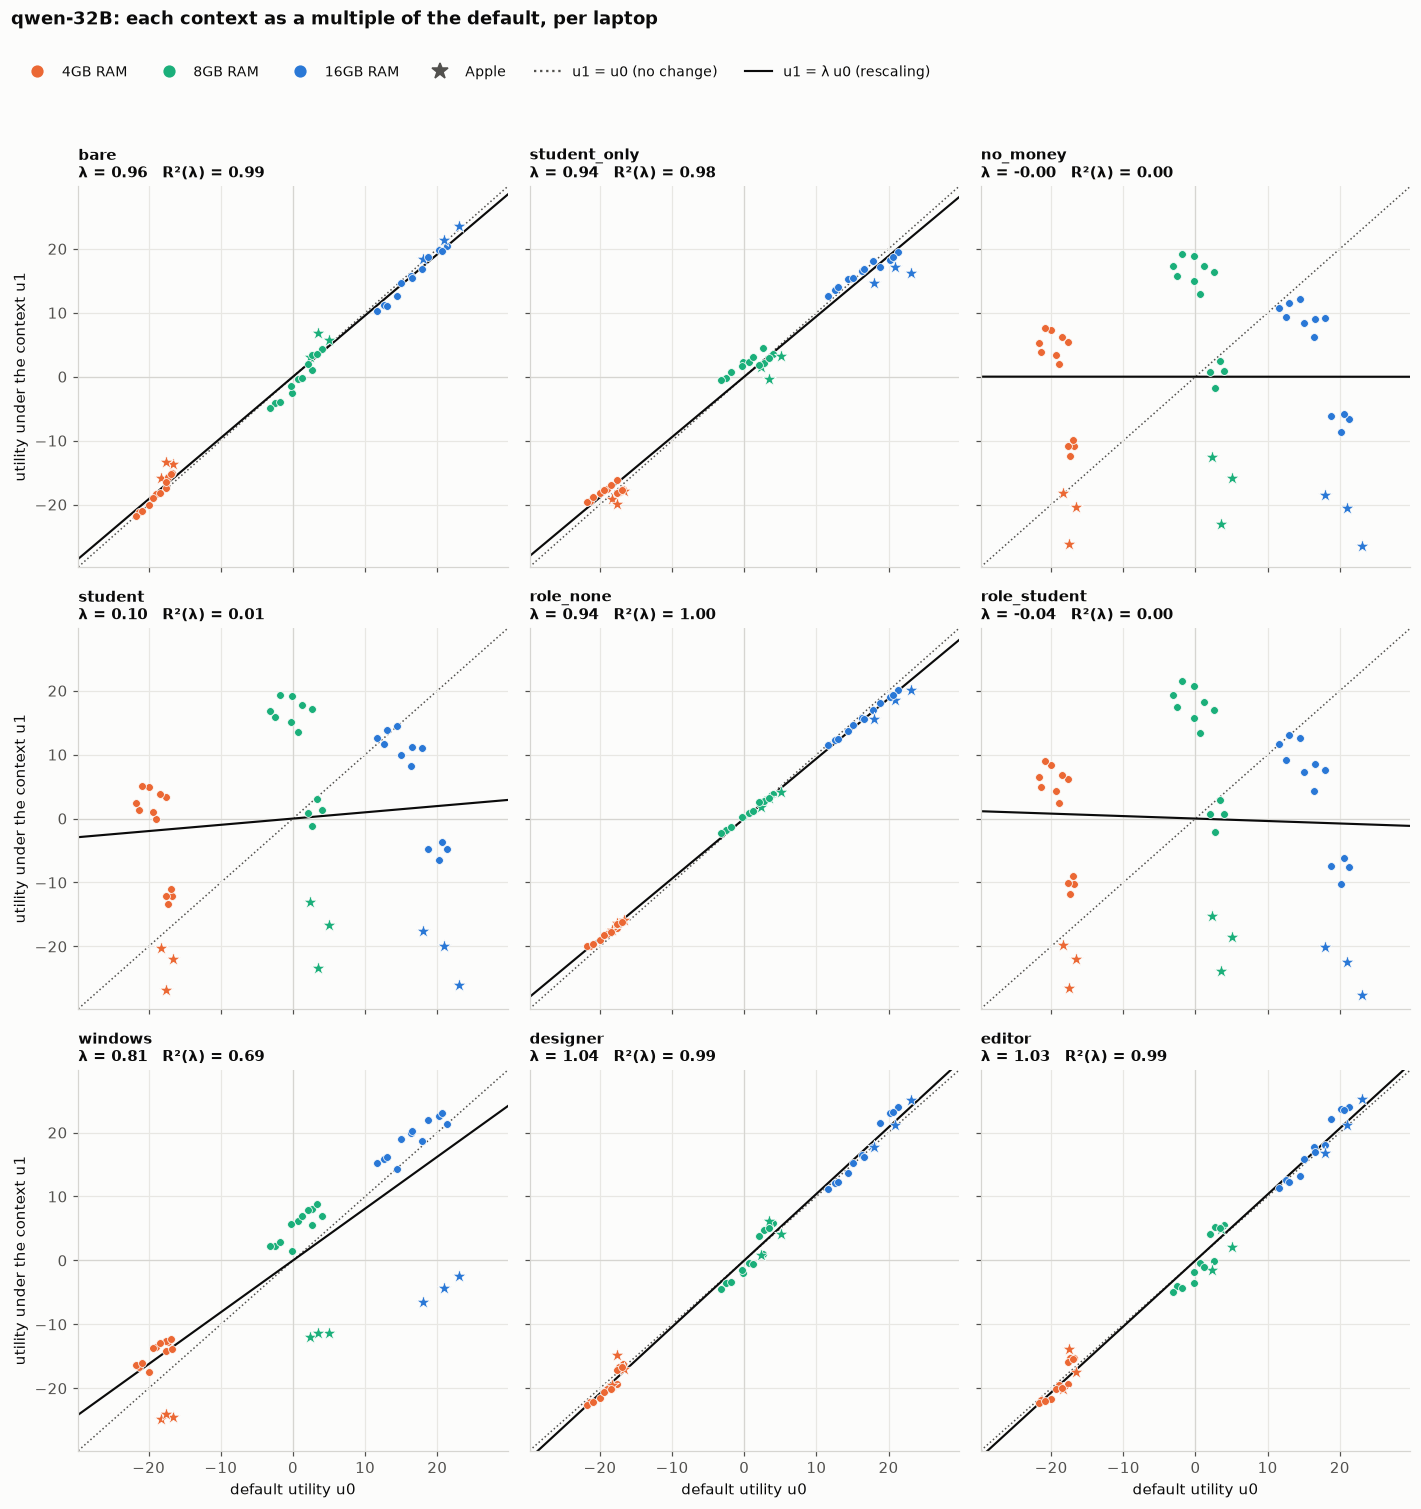

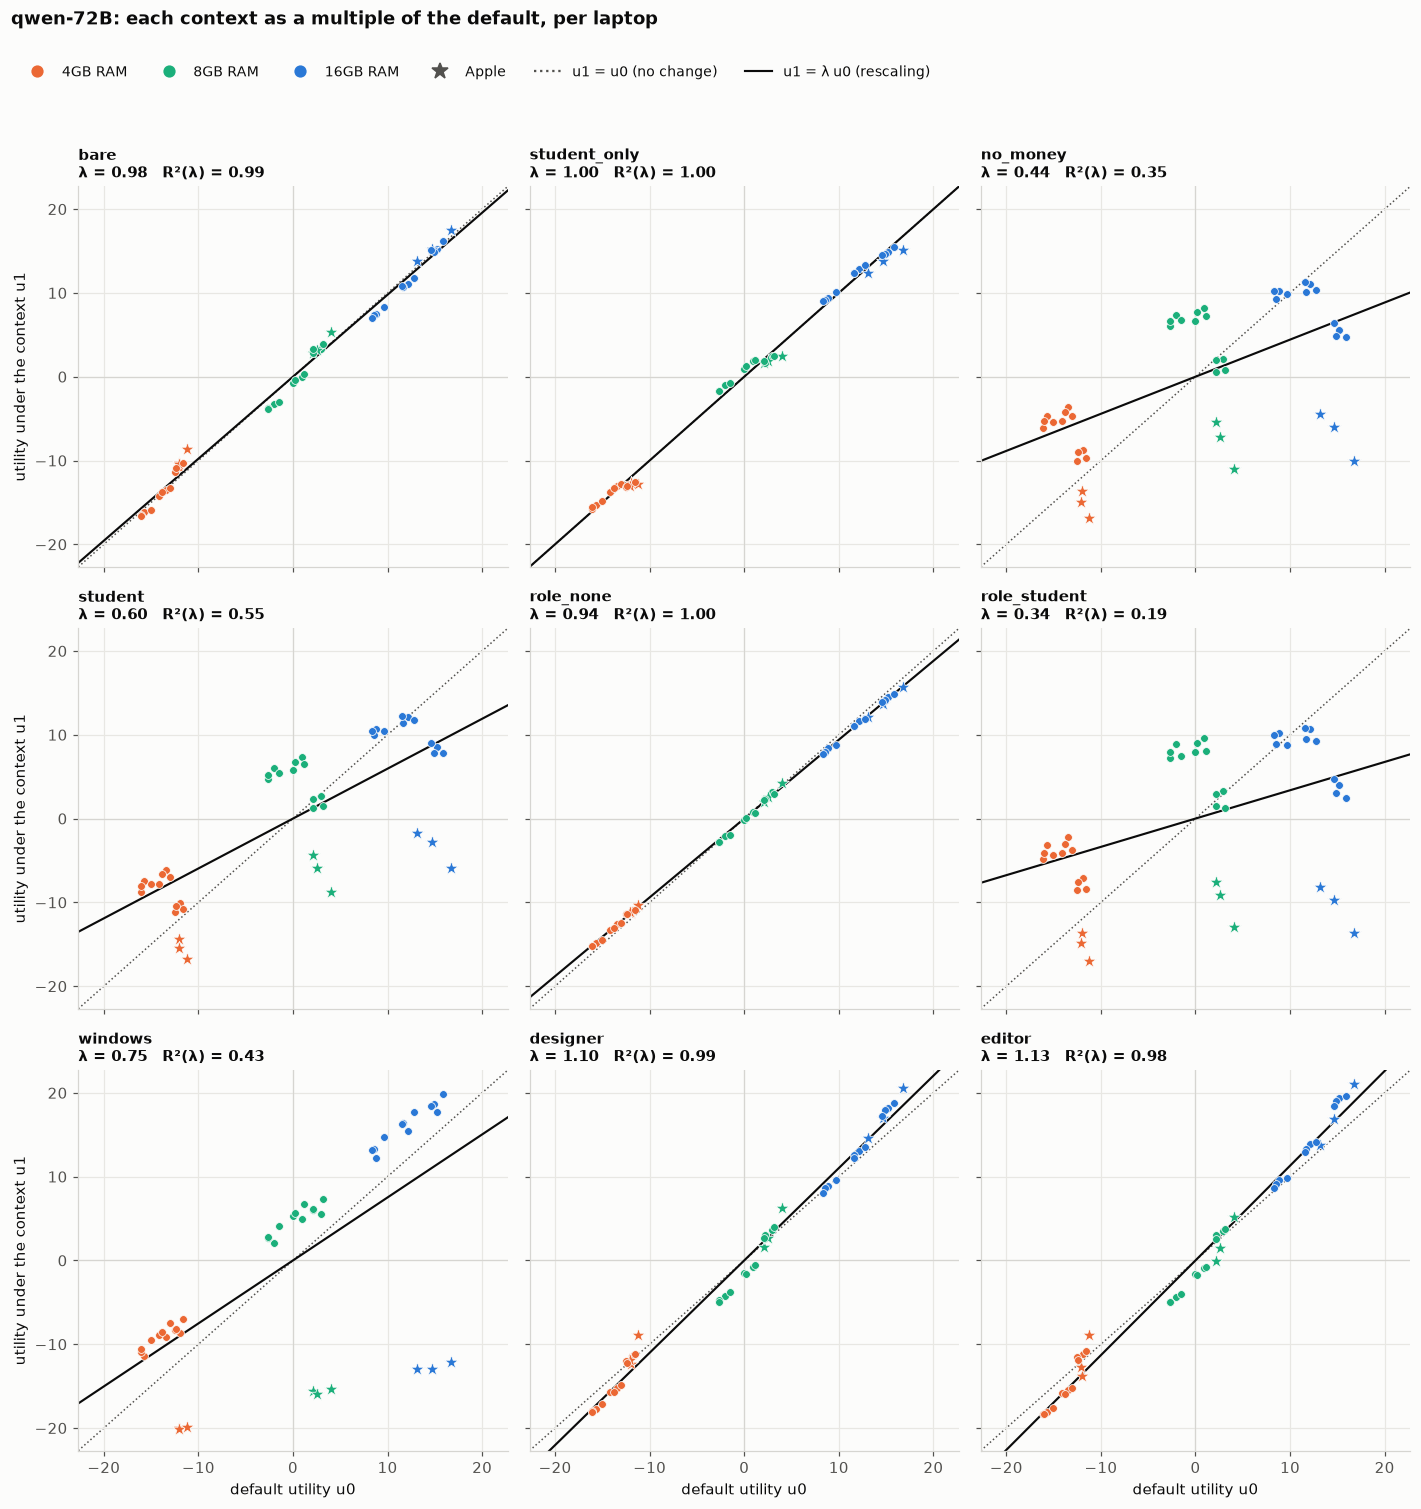

In [7]:
for m in PMODELS:
    ctxs = [c for c in FRAMES if m + (c,) in U]
    nc = 3
    nr = int(np.ceil(len(ctxs) / nc))
    u0 = U[m + ("default",)]
    lim = 1.08 * max(np.abs(U[m + (c,)]).max() for c in ctxs + ["default"])
    fig, axes = plt.subplots(nr, nc, figsize=(13, 4.3 * nr), sharex=True, sharey=True)
    for ax, ctx in zip(axes.flat, ctxs):
        u1 = U[m + (ctx,)]
        r = TL[(TL.model == f"{m[0]}-{m[1]}B") & (TL.context == ctx)].iloc[0]
        ax.grid(True, color="#e8e7e3")
        ax.axhline(0, color="#d6d5d1", lw=0.8); ax.axvline(0, color="#d6d5d1", lw=0.8)
        ax.plot([-lim, lim], [-lim, lim], color=INK_MUTED, lw=1, ls=":", zorder=1)
        ax.plot([-lim, lim], [-lim * r["lambda"], lim * r["lambda"]], color=INK, lw=1.4, zorder=2)
        for l in LAPTOPS:
            apple = l[0] == "Apple"
            ax.scatter(u0[IDX[l]], u1[IDX[l]], marker="*" if apple else "o", s=90 if apple else 26,
                       color=RAM_COLOR[l[2]], edgecolor=SURFACE, lw=0.5, zorder=3)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.set_title(f"{ctx}\nλ = {r['lambda']:.2f}   R²(λ) = {r['R2 multiplicative (u1 = λ u0)']:.2f}",
                     loc="left", fontsize=9.5, fontweight="bold")
    for ax in axes.flat[len(ctxs):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("default utility u0")
    for ax in axes[:, 0]:
        ax.set_ylabel("utility under the context u1")
    hs = [plt.Line2D([], [], marker="o", ls="", color=c, ms=7, label=f"{k} RAM") for k, c in RAM_COLOR.items()]
    hs += [plt.Line2D([], [], marker="*", ls="", color=INK_MUTED, ms=11, label="Apple"),
           plt.Line2D([], [], color=INK_MUTED, ls=":", label="u1 = u0 (no change)"),
           plt.Line2D([], [], color=INK, lw=1.4, label="u1 = λ u0 (rescaling)")]
    fig.legend(handles=hs, loc="upper left", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.01, 1.03))
    fig.suptitle(f"{m[0]}-{m[1]}B: each context as a multiple of the default, per laptop", x=0.01, y=1.06,
                 ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"C3_per_laptop_multiplicative_{m[0]}-{m[1]}B.png"), facecolor=SURFACE)
    plt.show()

## C4 — additive view: Δu per laptop (default = 0)

Rows = contexts, columns = the 45 laptops **ordered by default utility** (best on the left).
Red = the laptop gained, blue = lost. A purely multiplicative context with λ < 1 would look like a
smooth left-blue → right-red gradient (the top shrinks toward 0, the bottom rises toward 0);
anything else is additive. The bar above the columns marks Apple laptops.

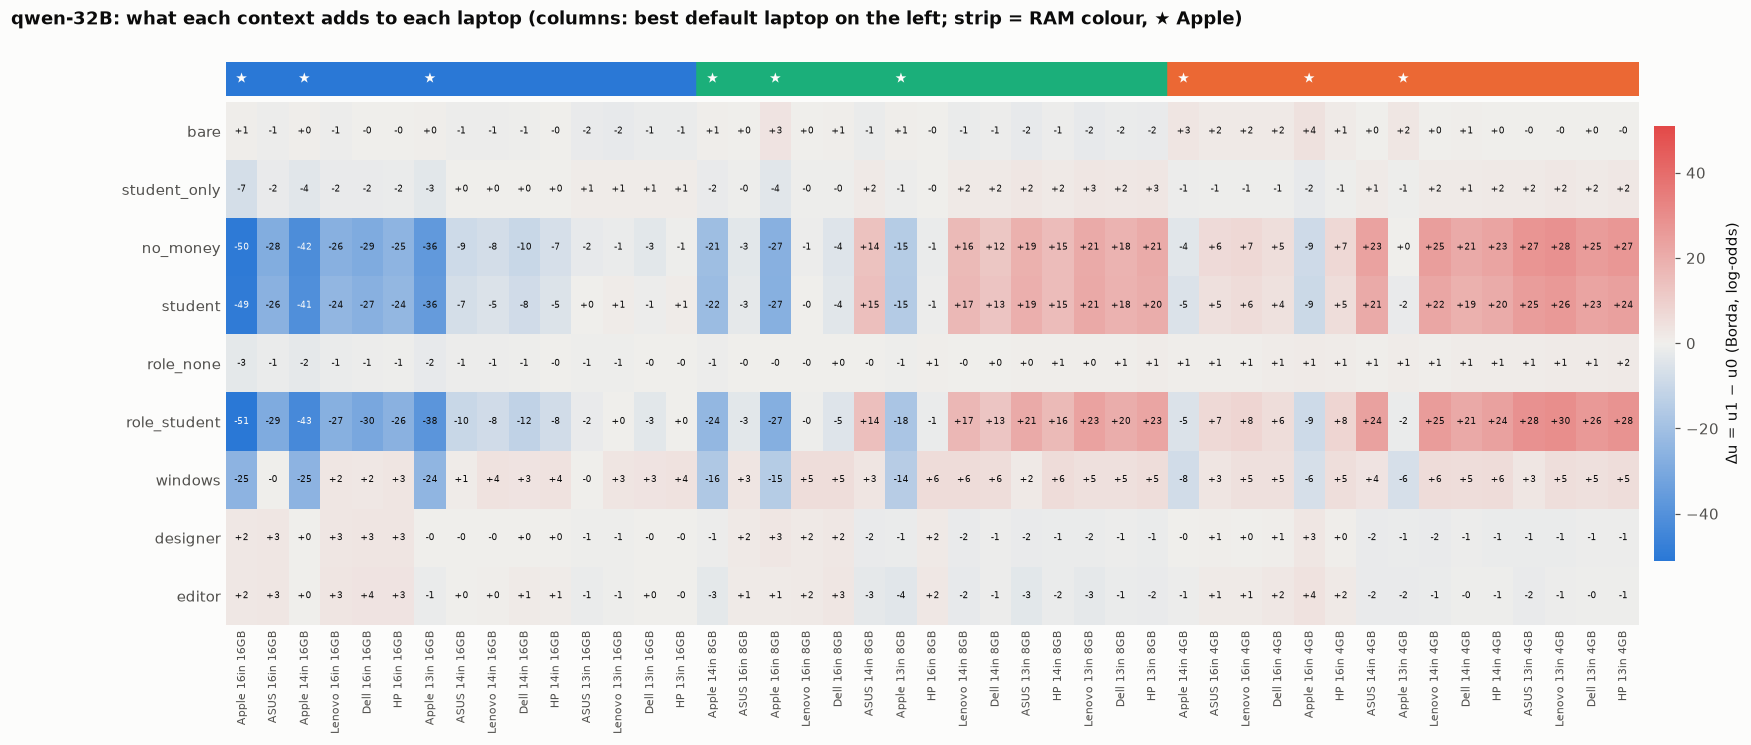

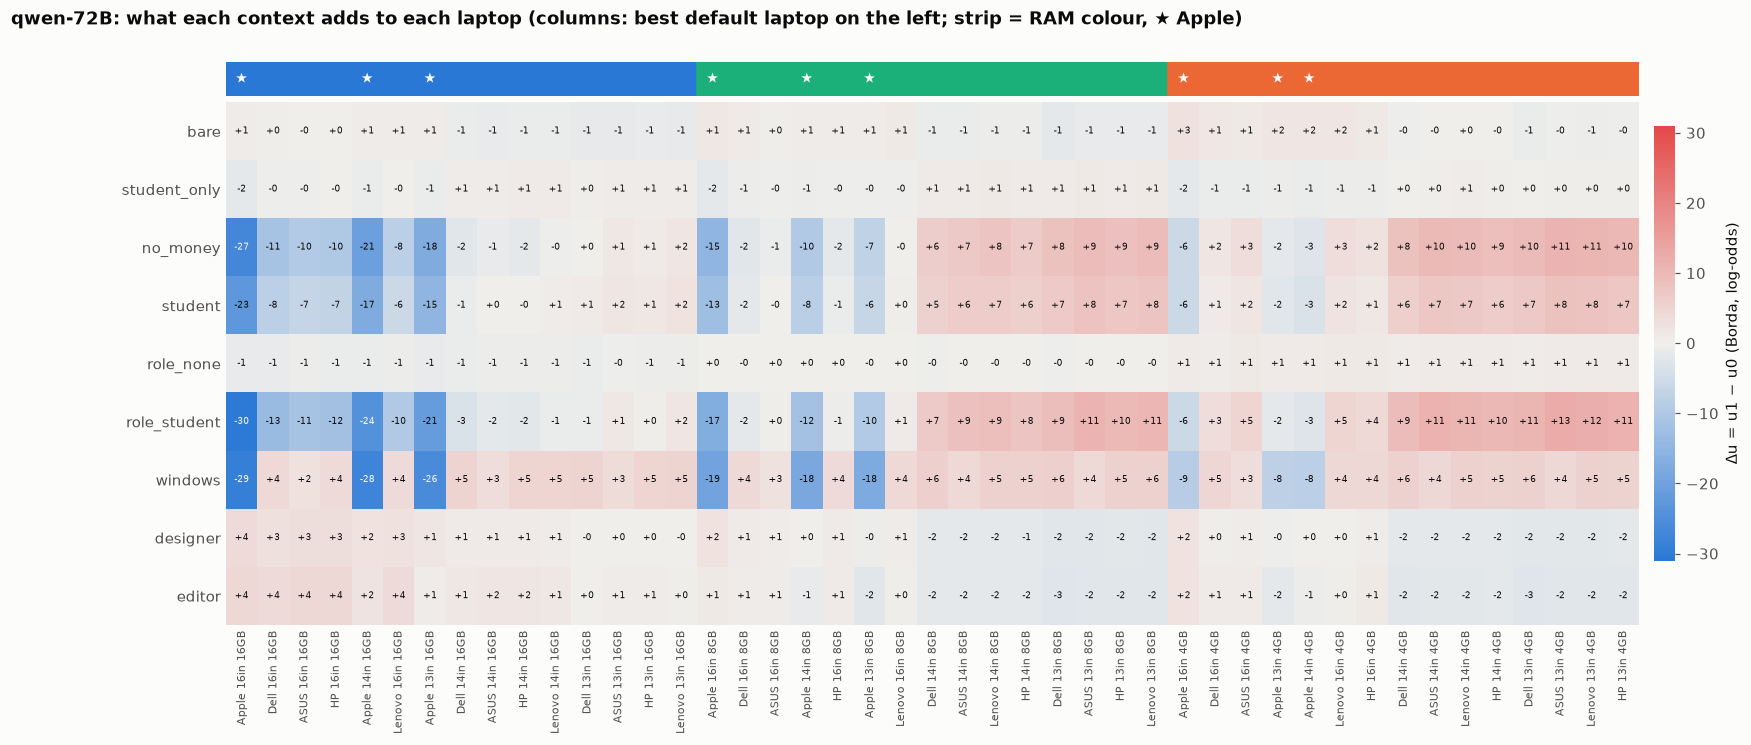

In [8]:
for m in PMODELS:
    ctxs = [c for c in FRAMES if m + (c,) in U]
    u0 = U[m + ("default",)]
    order = np.argsort(-u0)
    A = np.array([(U[m + (c,)] - u0)[order] for c in ctxs])
    va = np.ceil(np.abs(A).max())
    na = TwoSlopeNorm(vmin=-va, vcenter=0, vmax=va)
    fig, (axa, ax) = plt.subplots(2, 1, figsize=(17, 0.45 * len(ctxs) + 2.6), sharex=True,
                                  gridspec_kw={"height_ratios": [0.6, len(ctxs)], "hspace": 0.02})
    # strip: RAM colour + Apple mark, per column
    for j, k in enumerate(order):
        l = LAPTOPS[k]
        axa.add_patch(plt.Rectangle((j - 0.5, 0), 1, 1, color=RAM_COLOR[l[2]]))
        if l[0] == "Apple":
            axa.text(j, 0.5, "★", ha="center", va="center", color=SURFACE, fontsize=9)
    axa.set_ylim(0, 1); axa.set_yticks([]); axa.axis("off")
    im = ax.imshow(A, cmap=DIV, norm=na, aspect="auto")
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            r_, g_, b_, _ = DIV(na(A[i, j]))
            ax.text(j, i, f"{A[i, j]:+.0f}", ha="center", va="center", fontsize=6,
                    color=SURFACE if 0.299 * r_ + 0.587 * g_ + 0.114 * b_ < 0.55 else INK)
    ax.set_yticks(range(len(ctxs)), ctxs)
    ax.set_xticks(range(45), [f"{LAPTOPS[k][0]} {LAPTOPS[k][1].replace('-inch', 'in')} {LAPTOPS[k][2]}" for k in order],
                  rotation=90, fontsize=7)
    clean(ax)
    cb = fig.colorbar(im, ax=[axa, ax], fraction=0.015, pad=0.01)
    cb.set_label("Δu = u1 − u0 (Borda, log-odds)")
    cb.outline.set_visible(False)
    fig.suptitle(f"{m[0]}-{m[1]}B: what each context adds to each laptop (columns: best default laptop on the left; "
                 f"strip = RAM colour, ★ Apple)", x=0.01, y=0.95, ha="left", fontweight="bold")
    fig.savefig(os.path.join(FIGDIR, f"C4_per_laptop_additive_{m[0]}-{m[1]}B.png"), facecolor=SURFACE)
    plt.show()

---
# Bar charts — the effect of each context, per feature and per laptop

Four figures, one view each: **per feature** and **per laptop**, each **additive** (default = 0)
and **multiplicative** (default = 1). One model (argument below), the frames only (no contract),
one panel per context.

| | additive (default = 0) | multiplicative (default = 1) |
|---|---|---|
| **per feature** | `Δw = w1 − w0` for each of the 11 levels (FeatureBT weights) | `λ_f` per feature: `w1 ≈ λ_f · w0` inside the feature (least squares through 0) |
| **per laptop** | `Δu = u1 − u0` for each of the 45 laptops (Borda) | `u1 / u0` for each laptop |

**Why the multiplicative view is per feature and not per level.** Weights are centred inside each
feature, so the middle level (14", 8GB) always sits near 0 and `w1 / w0` explodes there. One λ per
feature uses all its levels at once and stays stable. **The same problem hits the per-laptop
ratio:** laptops in the middle of the default ranking have `u0 ≈ 0`. Those bars are drawn **grey**
(`|u0|` below 20% of the largest `|u0|`) and every ratio is clipped at ±3.

In [9]:
BAR_MODEL = ("qwen", "32")

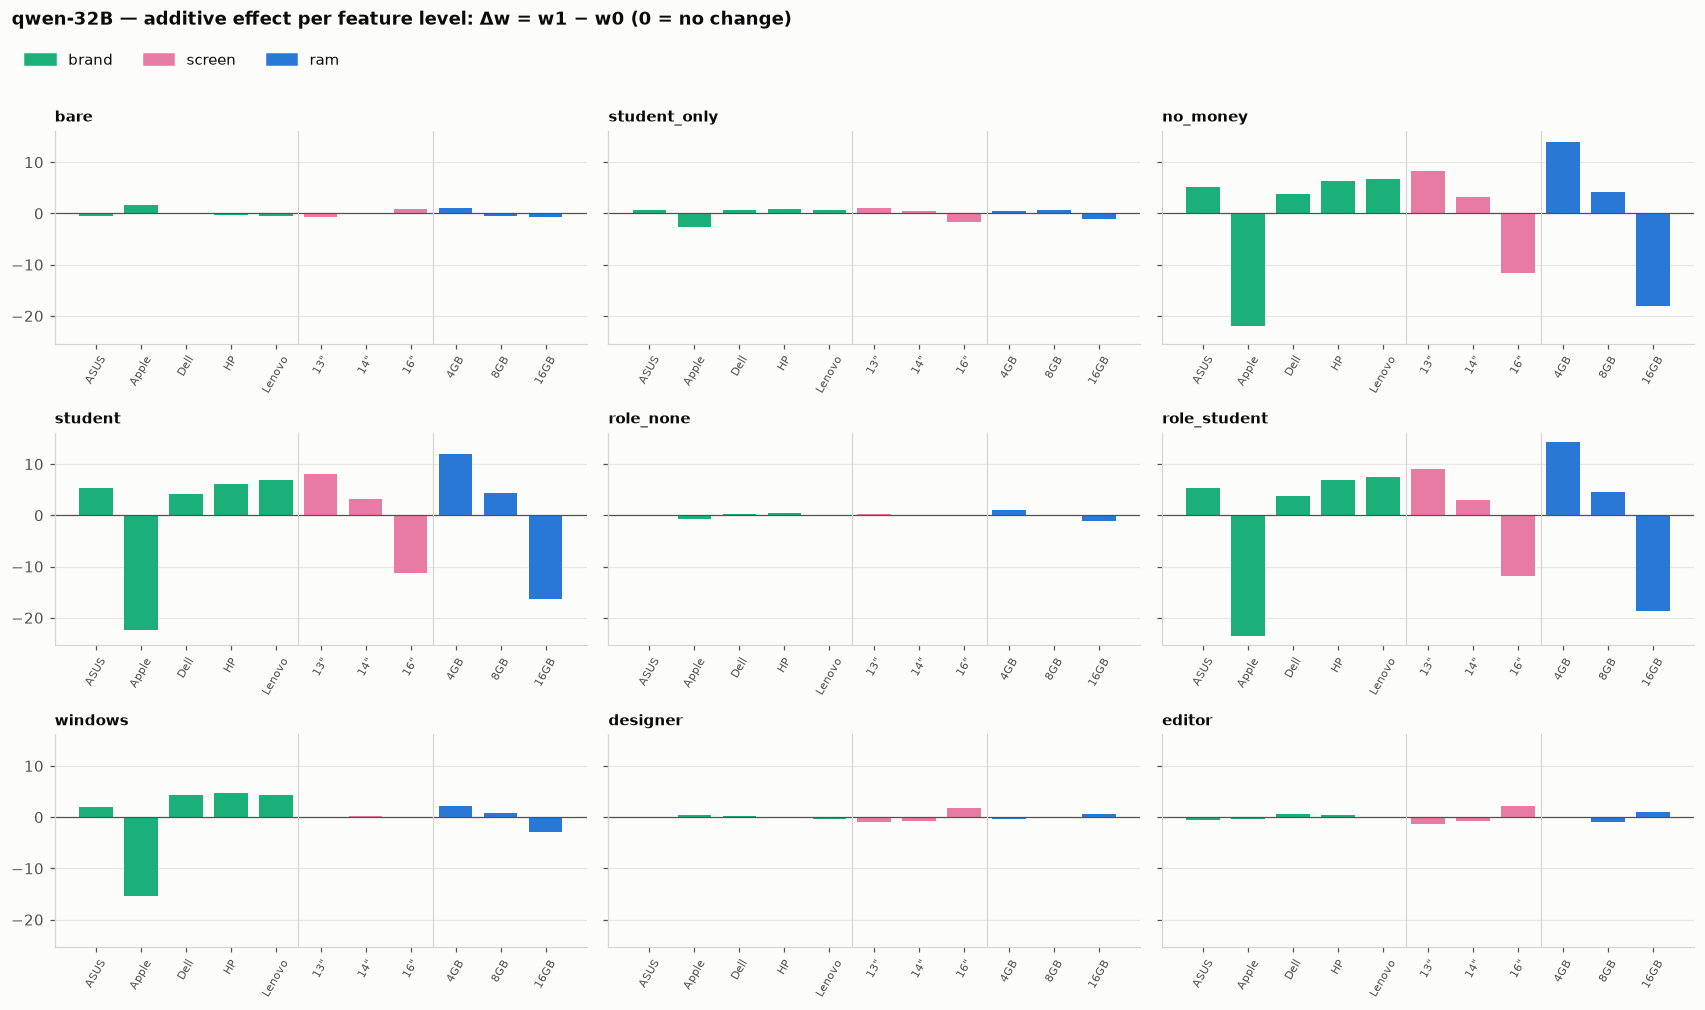

In [10]:
FEAT_COL = {"brand": "#1baf7a", "screen": "#e87ba4", "ram": "#2a78d6"}
m = BAR_MODEL
ctxs = [c for c in FRAMES if m + (c,) in W]
w0 = W[m + ("default",)]
mname = f"{m[0]}-{m[1]}B"


def grid_axes(n, ncol=3, h=2.9, w=5.2, sharey=True):
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), sharey=sharey, squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


# ---- B1: per feature level, additive
fig, axes = grid_axes(len(ctxs))
for ax, ctx in zip(axes, ctxs):
    d = W[m + (ctx,)] - w0
    ax.bar(range(len(LV)), d, color=[FEAT_COL[f] for f, _ in LV], width=0.75, zorder=2)
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    ax.grid(True, axis="y", color="#e8e7e3")
    ax.set_xticks(range(len(LV)), [l.replace("-inch", '"') for _, l in LV], rotation=60, fontsize=7.5)
    for k in (5, 8):
        ax.axvline(k - 0.5, color="#d6d5d1", lw=0.8)
    ax.set_title(ctx, loc="left", fontweight="bold", fontsize=10)
for ax in list(axes)[::3]:
    ax.set_ylabel("Δw (log-odds)")
hs = [plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in FEAT_COL.items()]
fig.legend(handles=hs, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.01, 1.02))
fig.suptitle(f"{mname} — additive effect per feature level: Δw = w1 − w0 (0 = no change)", x=0.01, y=1.05,
             ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, f"B1_feature_additive_{mname}.png"), facecolor=SURFACE)
plt.show()

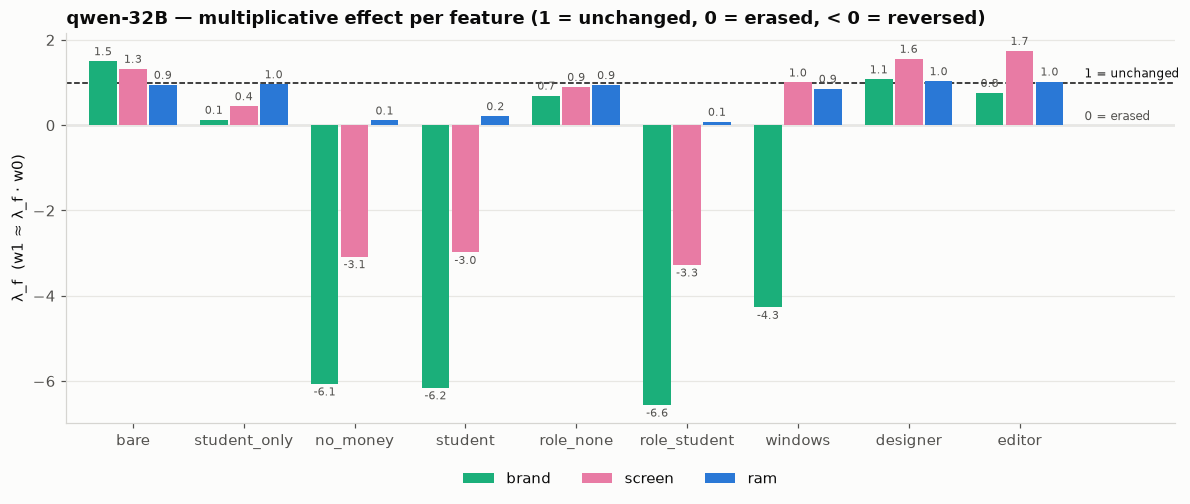

In [11]:
# ---- B2: per feature, multiplicative (one lambda per feature)
L = pd.DataFrame({ctx: {f: (W[m + (ctx,)][feat_slice(f)] @ w0[feat_slice(f)]) / (w0[feat_slice(f)] @ w0[feat_slice(f)])
                        for f in LEVELS} for ctx in ctxs}).T
fig, ax = plt.subplots(figsize=(13, 4.6))
x = np.arange(len(ctxs))
for j, f in enumerate(LEVELS):
    bars = ax.bar(x + (j - 1) * 0.27, L[f], 0.25, color=FEAT_COL[f], label=f, zorder=2)
    for b, v in zip(bars, L[f]):
        ax.text(b.get_x() + b.get_width() / 2, v + (0.08 if v >= 0 else -0.08), f"{v:.1f}", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=7, color=INK_MUTED)
ax.axhline(1, color=INK, lw=1, ls="--", zorder=1)
ax.axhline(0, color=INK_MUTED, lw=0.8, zorder=1)
ax.text(len(ctxs) - 0.45, 1.05, " 1 = unchanged", va="bottom", fontsize=8, color=INK)
ax.text(len(ctxs) - 0.45, 0.05, " 0 = erased", va="bottom", fontsize=8, color=INK_MUTED)
ax.grid(True, axis="y", color="#e8e7e3")
ax.set_xticks(x, ctxs)
ax.set_xlim(-0.6, len(ctxs) + 0.4)
ax.set_ylabel("λ_f  (w1 ≈ λ_f · w0)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.09))
ax.set_title(f"{mname} — multiplicative effect per feature (1 = unchanged, 0 = erased, < 0 = reversed)",
             loc="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, f"B2_feature_multiplicative_{mname}.png"), facecolor=SURFACE)
plt.show()

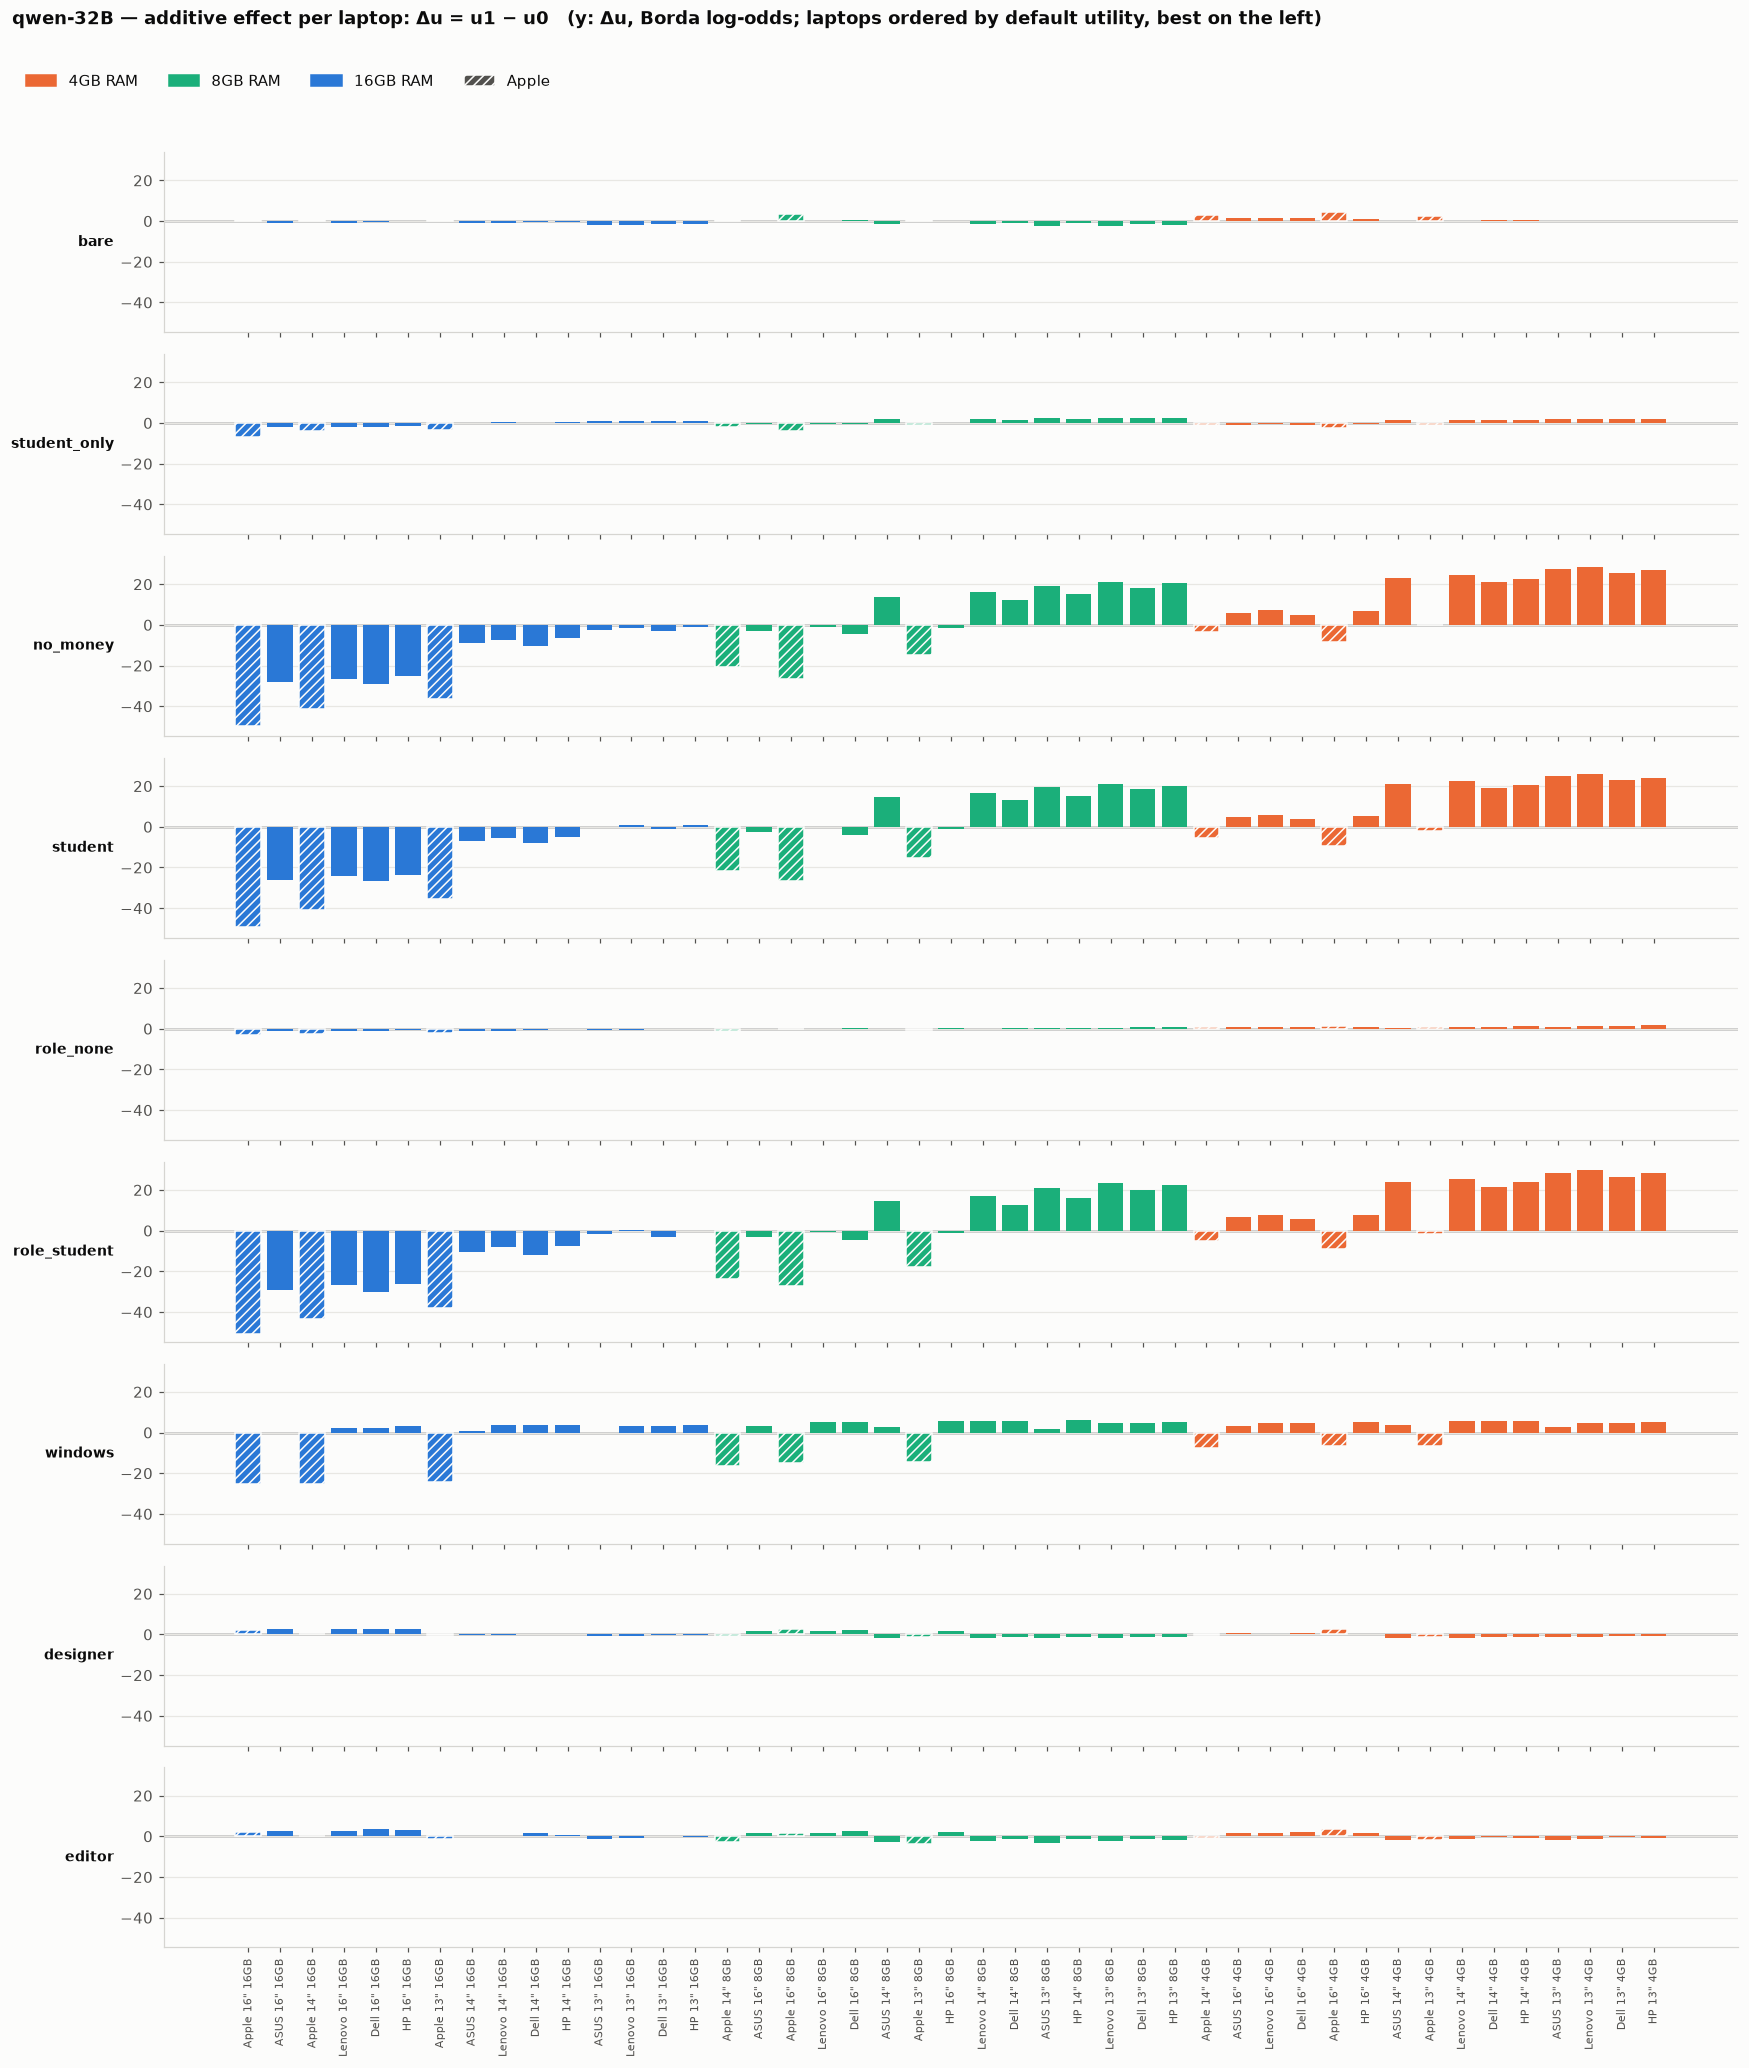

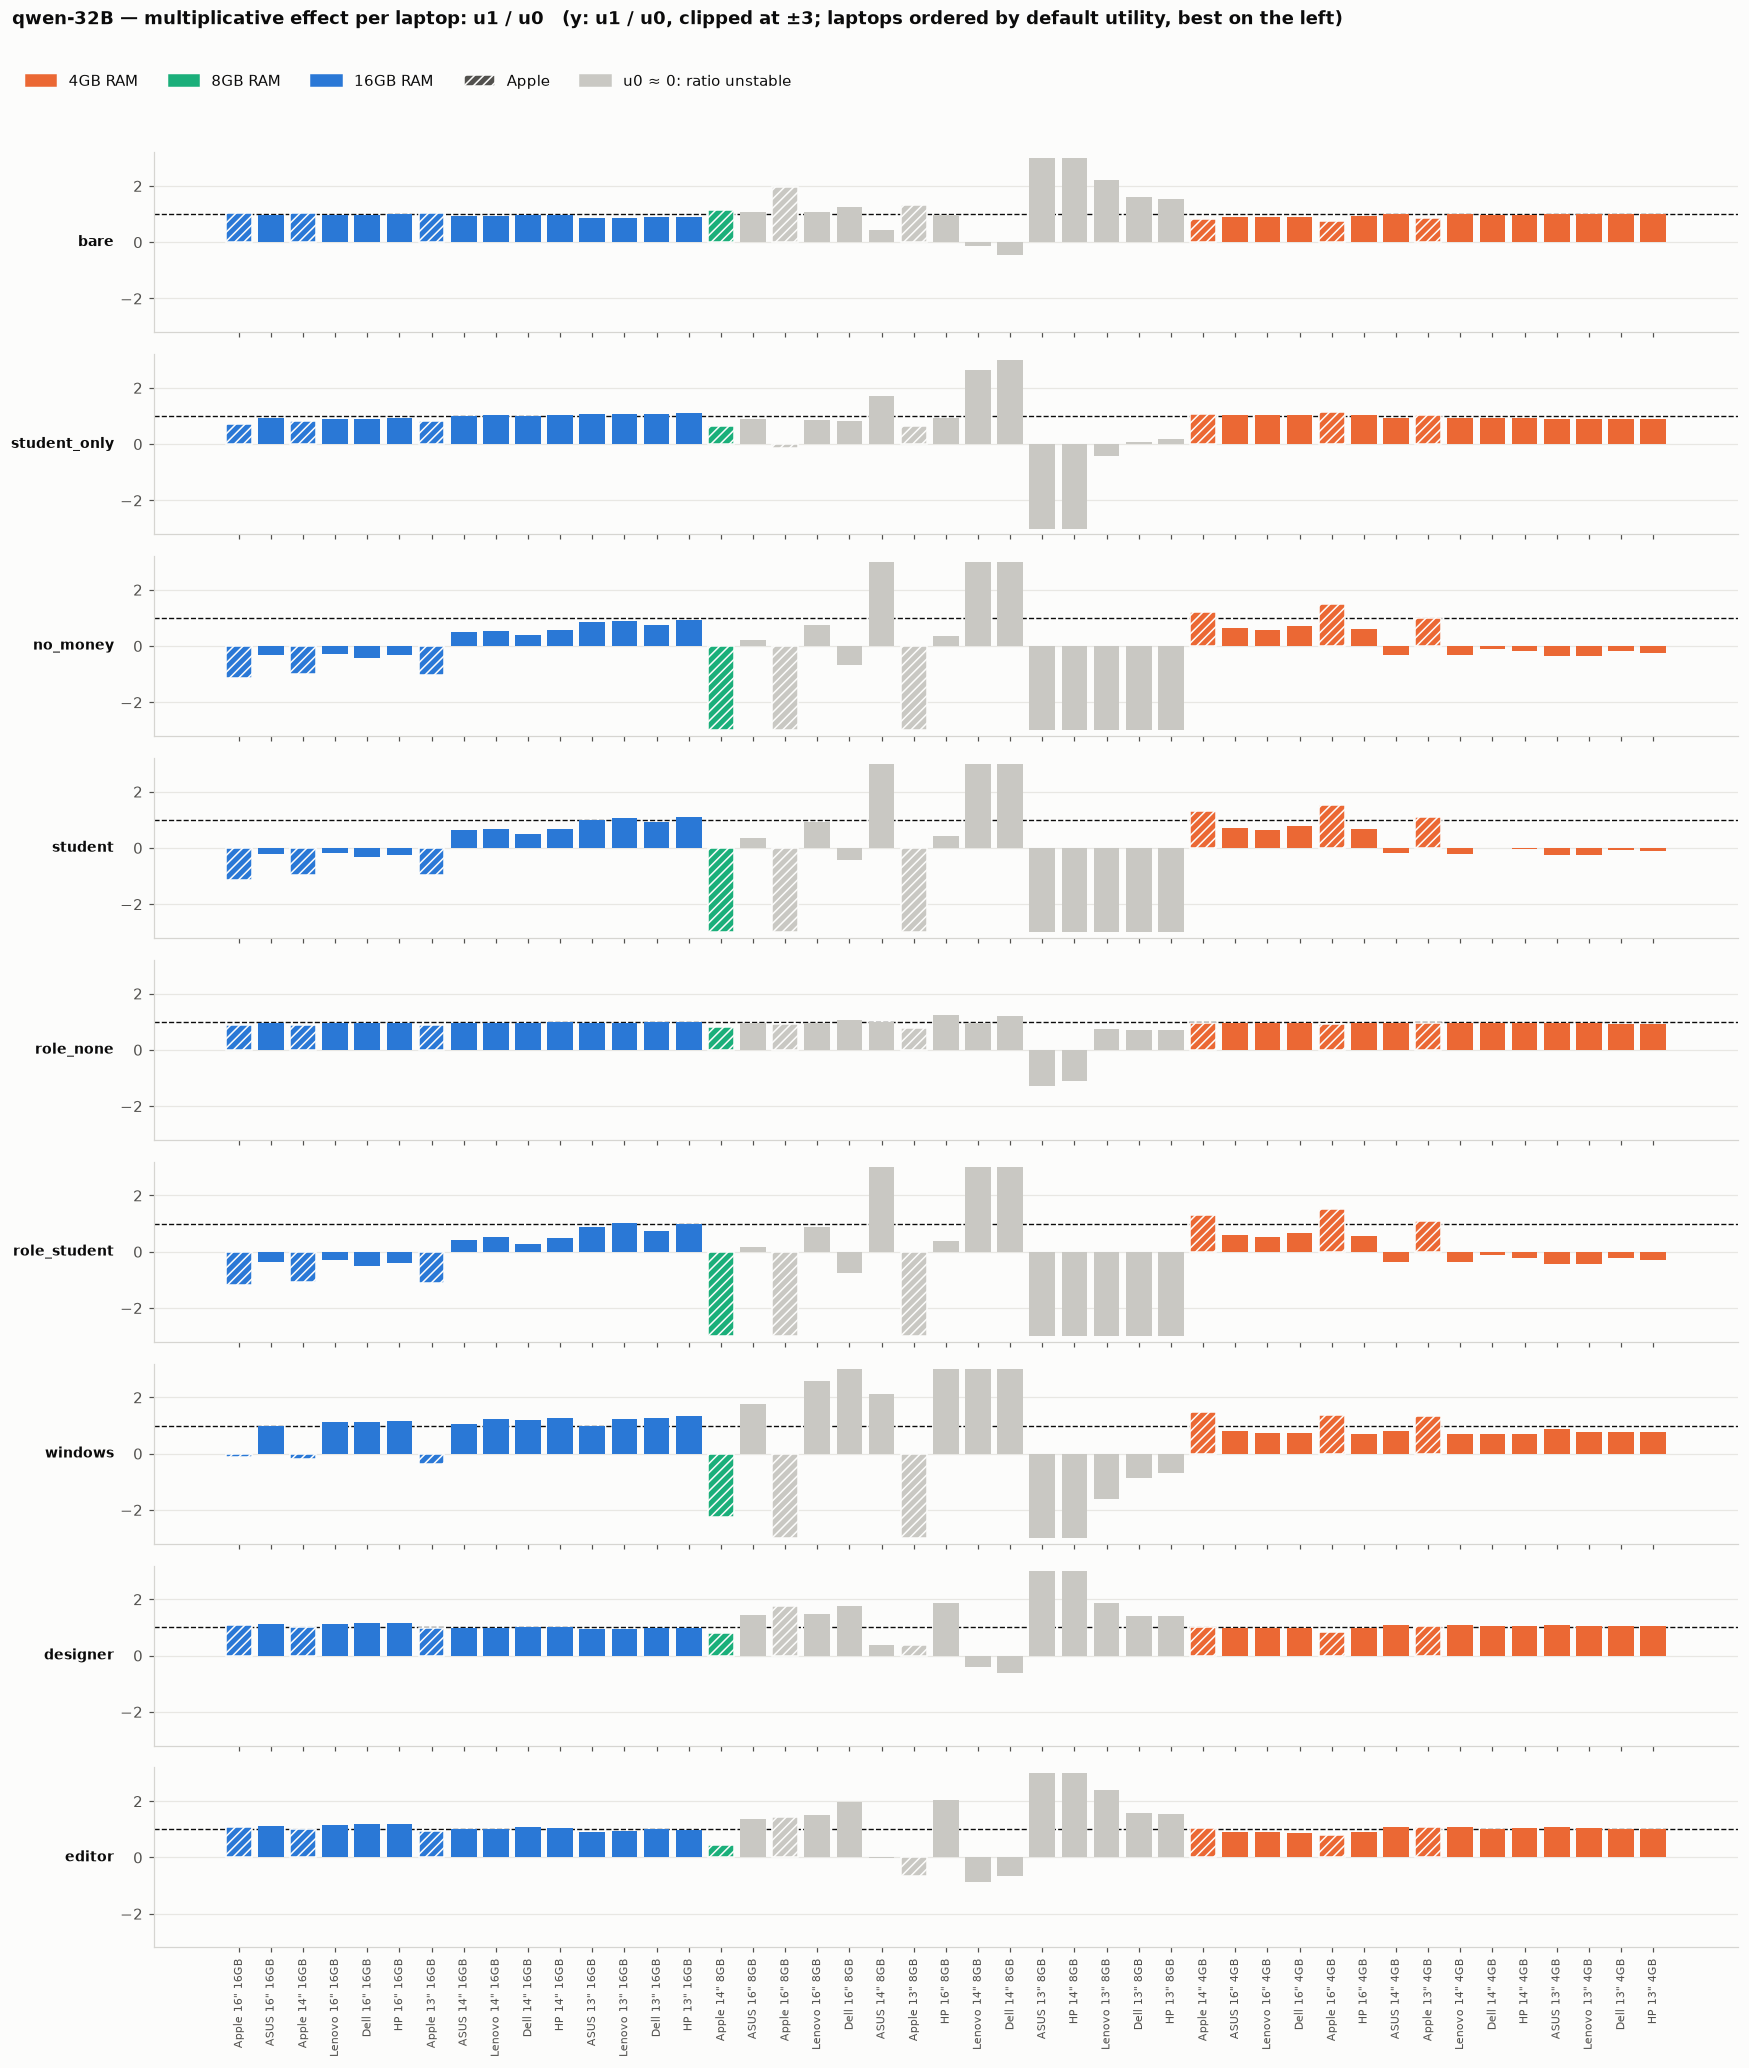

In [12]:
# ---- B3 / B4: per laptop, laptops ordered by default utility (best on the left)
u0 = U[m + ("default",)]
order = np.argsort(-u0)
labels = [f"{LAPTOPS[k][0]} {LAPTOPS[k][1].replace('-inch', '\"')} {LAPTOPS[k][2]}" for k in order]
lap_cols = [RAM_COLOR[LAPTOPS[k][2]] for k in order]
apple = [LAPTOPS[k][0] == "Apple" for k in order]
small = np.abs(u0[order]) < 0.2 * np.abs(u0).max()                 # u0 ~ 0: the ratio is unstable


def laptop_bars(values, ylabel, title, fname, ref, ylim=None, grey=None):
    fig, axes = plt.subplots(len(ctxs), 1, figsize=(16, 1.9 * len(ctxs) + 1.2), sharex=True, sharey=True)
    for ax, ctx in zip(axes, ctxs):
        v = values(ctx)
        cols = ["#c9c8c3" if (grey is not None and grey[i]) else c for i, c in enumerate(lap_cols)]
        bars = ax.bar(range(45), v, color=cols, width=0.8, zorder=2)
        for b, a in zip(bars, apple):
            if a:
                b.set_hatch("////"); b.set_edgecolor(SURFACE)
        ax.axhline(ref, color=INK, lw=0.9, ls="--" if ref else "-", zorder=1)
        ax.grid(True, axis="y", color="#e8e7e3")
        if ylim:
            ax.set_ylim(*ylim)
        ax.set_ylabel(ctx, rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    axes[-1].set_xticks(range(45), labels, rotation=90, fontsize=7)
    hs = [plt.Rectangle((0, 0), 1, 1, color=c, label=f"{r} RAM") for r, c in RAM_COLOR.items()]
    hs.append(plt.Rectangle((0, 0), 1, 1, facecolor=INK_MUTED, hatch="////", edgecolor=SURFACE, label="Apple"))
    if grey is not None:
        hs.append(plt.Rectangle((0, 0), 1, 1, color="#c9c8c3", label="u0 ≈ 0: ratio unstable"))
    fig.legend(handles=hs, loc="upper left", ncol=len(hs), frameon=False, bbox_to_anchor=(0.01, 1.0))
    fig.suptitle(title + f"   (y: {ylabel}; laptops ordered by default utility, best on the left)", x=0.01, y=1.025,
                 ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()


laptop_bars(lambda c: (U[m + (c,)] - u0)[order], "Δu, Borda log-odds",
            f"{mname} — additive effect per laptop: Δu = u1 − u0", f"B3_laptop_additive_{mname}.png", ref=0)
laptop_bars(lambda c: np.clip((U[m + (c,)] / u0)[order], -3, 3), "u1 / u0, clipped at ±3",
            f"{mname} — multiplicative effect per laptop: u1 / u0", f"B4_laptop_multiplicative_{mname}.png",
            ref=1, ylim=(-3.2, 3.2), grey=small)